# 02 - Feature engineering

Builds the feature table used by the classification and clustering notebooks.
The feature code is in `src/features.py`. Every feature uses only what is known at filing time.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from load_data import load_raw
from prepare import clean, build_dataset
from features import build_features, feature_groups

FIG = ROOT / "figures"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

In [2]:
df = clean(load_raw())
data = build_dataset(df)
print(len(df), "rows in the file,", len(data), "in the modeling dataset")

Loaded 364,115 rows, dropped 123 malformed rows


364115 rows in the file, 227489 in the modeling dataset


## 1. Leakage check: is the Hebrew owner name filled at filing time?

In notebook 01 the Hebrew owner name was the strongest single signal. If the Patent Office adds it
only during examination or registration, it would leak the outcome. A simple test: applications that are
**still pending** haven't been decided yet. If they already have the Hebrew name at the same rate as decided
applications from the same years, the field is filled at filing.

In [3]:
national = df["route"] == "לאומי"
recent = df["filing_year"].between(2024, 2026)
check = (df[national & recent]
         .assign(group=lambda x: np.where(x["is_decided"], "decided", "pending"),
                 has_owner_he=lambda x: x["owner_he"].notna(),
                 has_mark_he=lambda x: x["mark_text_he"].notna())
         .groupby(["filing_year", "group"])[["has_owner_he", "has_mark_he"]]
         .agg(["mean", "size"]).round(3))
check

has_owner_he       has_mark_he      
                            mean  size        mean  size
filing_year group                                       
2024        decided        0.569  4015       0.261  4015
            pending        0.509    57       0.211    57
2025        decided        0.606  3947       0.273  3947
            pending        0.593   334       0.305   334
2026        decided        0.681  1038       0.281  1038
            pending        0.618  3143       0.270  3143

Pending applications have the Hebrew owner name at almost the same rate as decided ones
(the gap is small and in both directions for the mark text), so the field is filled when the application is filed.
We keep it as a feature.

## 2. Build the features

| Group | Features |
|---|---|
| Filing | year, month, route, registration type, priority claim, external registration |
| Nice classes | number of classes, 45 binary columns |
| Vienna codes | number of codes, has codes, 29 binary columns (top-level categories) |
| Mark text | script (Hebrew / Latin / both / none), length, words, has digit, figurative flag |
| Goods | length in English and Hebrew, has Hebrew list, English text (for TF-IDF in notebook 03) |
| Owner / attorney | company name, Hebrew owner name, has attorney, prior filings (log), past failure rate |

**History features.** `owner_prior_filings` and `attorney_prior_filings` count applications filed strictly
earlier by the same name (any year, any status; earlier filings are public).
`owner_fail_rate` and `attorney_fail_rate` are smoothed past failure rates:

rate = (earlier failures + 20 x global rate) / (earlier applications + 20)

For training rows only earlier **training** applications are used; for test rows the rate comes from all
training applications. Test labels are never used. One limitation: an earlier application may not have
been decided yet when the current one was filed, so these rates are a bit optimistic.

In [4]:
feats = build_features(df, data)
numeric, categorical, text = feature_groups(feats.columns)
print(feats.shape)
print(f"{len(numeric)} numeric, {len(categorical)} categorical, 1 text column")
feats.drop(columns=[c for c in feats if c.startswith(("nice_", "vienna_"))]).head()

(227489, 104)
95 numeric, 3 categorical, 1 text column


,row_id,filing_date,filing_year,filing_month,is_train,route,registration_type,is_figurative,priority_claim,external_registration,...,goods_text,owner_is_company,owner_has_he_name,has_attorney,owner_prior_filings,attorney_prior_filings,owner_fail_rate,attorney_fail_rate,attorney_name,failed
0,93542,2000-11-19,2000,11,True,national,trade_service,1,0,0,...,Cosmetics and cleaning preparations; all inclu...,1,0,1,1.098612,3.970292,0.152836,0.152836,steven slom adv,0
1,95894,2000-02-21,2000,2,True,national,trade_service,0,0,0,...,Retail services; store services; advertising a...,0,1,1,1.945910,8.479076,0.193177,0.155437,wolff bregman and goller,1
2,95896,2000-02-21,2000,2,True,national,trade_service,0,0,0,...,"Vehicles; apparatus for locomotion by land, ai...",0,1,1,1.945910,8.479076,0.193177,0.155437,wolff bregman and goller,1
3,95912,2000-01-03,2000,1,True,national,trade_service,0,0,0,...,Games and playthings (except ordinary playing ...,0,1,1,0.000000,1.098612,0.152836,0.152836,harish adv,0
4,95913,2000-01-02,2000,1,True,national,trade_service,0,0,0,...,Framing of pictures and works of art.,0,1,1,0.000000,0.000000,0.152836,0.152836,ariel lerman adv,0


## 3. Single-feature signal (ROC-AUC of each feature alone)

An AUC of 0.5 means no signal. Values below 0.5 mean the feature is related to failure in the opposite
direction. Comparing train and test shows which features stay stable over time.

In [5]:
summary_cols = [c for c in numeric if not c.startswith(("nice_", "vienna_"))]
rows = []
for col in summary_cols:
    row = {"feature": col}
    for name, mask in [("train", feats["is_train"]), ("test", ~feats["is_train"])]:
        auc = roc_auc_score(feats.loc[mask, "failed"], feats.loc[mask, col])
        row[f"auc_{name}"] = round(auc, 3)
    rows.append(row)
auc_table = pd.DataFrame(rows)
auc_table["strength"] = (auc_table["auc_train"] - 0.5).abs()
auc_table.sort_values("strength", ascending=False).drop(columns="strength")

,feature,auc_train,auc_test
20,attorney_fail_rate,0.651,0.586
19,owner_fail_rate,0.651,0.597
18,attorney_prior_filings,0.371,0.434
15,owner_has_he_name,0.629,0.569
9,mark_words,0.599,0.588
8,mark_len,0.597,0.599
11,goods_en_len,0.408,0.435
17,owner_prior_filings,0.419,0.430
7,has_vienna,0.439,0.427
6,n_vienna,0.440,0.424


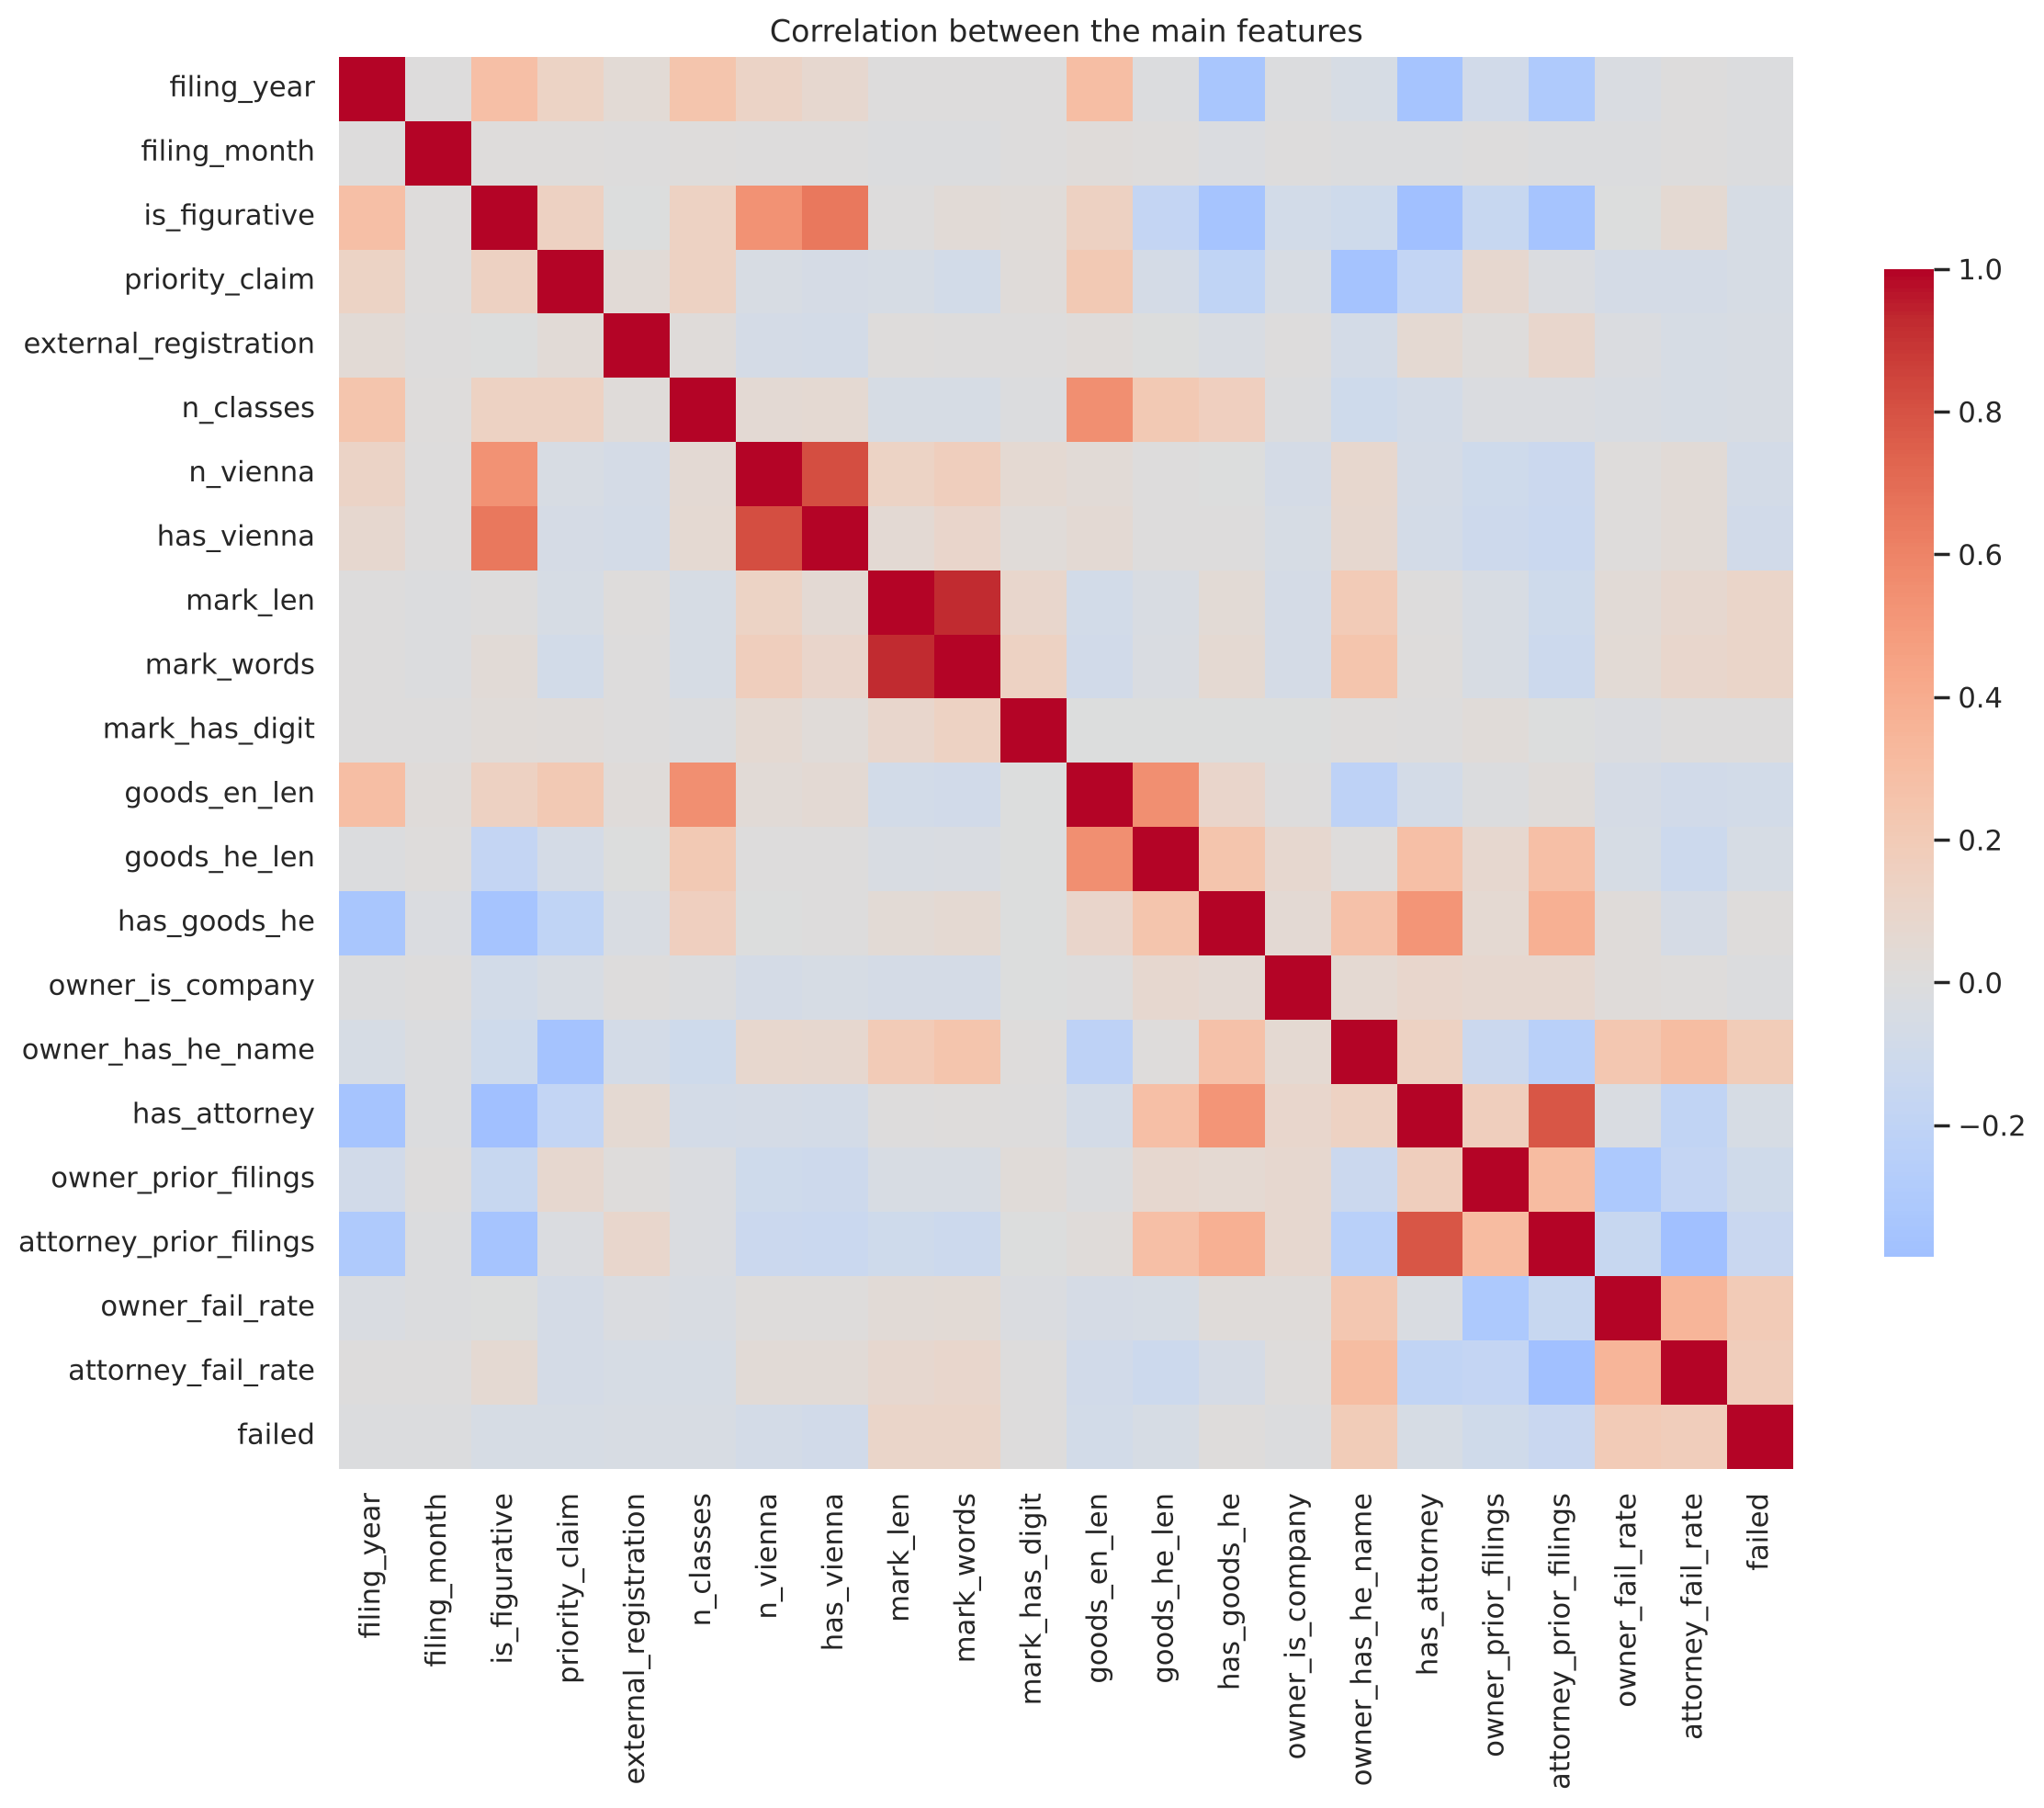

Pairs with |correlation| > 0.7:
mark_len      mark_words                0.928850
n_vienna      has_vienna                0.814671
has_attorney  attorney_prior_filings    0.787052
dtype: float64


In [6]:
corr = feats[summary_cols + ["failed"]].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Correlation between the main features")
plt.tight_layout()
plt.savefig(FIG / "feature_correlation.png", dpi=120)
plt.show()

high = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
        .loc[lambda s: s.abs() > 0.7].sort_values(ascending=False))
print("Pairs with |correlation| > 0.7:")
print(high)

## 4. Save

In [7]:
out = PROCESSED / "features.parquet"
feats.to_parquet(out, index=False)
print(out.relative_to(ROOT), f"{out.stat().st_size / 1e6:.1f} MB")

data/processed/features.parquet 48.5 MB


Notes:

1. The history features (`owner_fail_rate`, `attorney_fail_rate`) and the Hebrew owner name carry the most signal.
2. Their AUC drops on the test period, so part of their signal doesn't carry over to new years.
3. `owner_is_company` has almost no signal by itself.
4. `goods_en_len` is capped at 2,000 characters in the source file.